In [1]:
import sys, warnings, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
ROOT = Path.cwd(); sys.path.insert(0, str(ROOT))
FIG, TAB, PRED = ROOT/"results"/"figures", ROOT/"results"/"tables", ROOT/"results"/"predictions"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})
def savefig(name):
    plt.savefig(FIG/f"{name}.png", bbox_inches="tight"); print("saved ->", f"results/figures/{name}.png")
pd.set_option("display.width", 160, "display.max_columns", 40, "display.float_format", lambda v: f"{v:,.3f}")

# 06 · Time-resolved weather: acquisition, quality control and 16-week lag construction

**Why this notebook exists.** Phase 1 ended with an honest limitation: the supplied `Data.csv` only contains *seasonal
aggregates* (`IMD_RF`, `IMD_Tmax`, `SD_RF_jun_nov`), so the central hypothesis of the proposal - *the timing of rainfall in the
weeks before harvest carries predictive information that a seasonal total hides* - could not be tested, and synthetic lags were
(correctly) forbidden.

This notebook removes that limitation with **real, independently observed daily weather**:

| Item | Source | Resolution |
|---|---|---|
| Daily rainfall | India Meteorological Department (IMD) gridded product, retrieved with `imdlib` (`scripts/12_download_imd_grid.py`) | 0.25° x 0.25°, daily, 1990-2017 |
| Daily maximum temperature | IMD gridded product | 1° x 1°, daily |
| District location | Open-Meteo / OSM Nominatim geocoders (district HQ), then QC-refined (`scripts/14_refine_geolocation.py`) | point |

IMD is the *same agency* that produced the `IMD_RF` / `IMD_Tmax` columns in the yield dataset, which makes it the most consistent
choice and lets us **validate the extraction against the dataset's own rainfall column**.

## 1 · Where are the 384 districts?

source
open-meteo          276
nominatim            73
alias:open-meteo     35

sampling point moved by QC refinement: 74 of 384


saved -> results/figures/p2_06_district_map.png


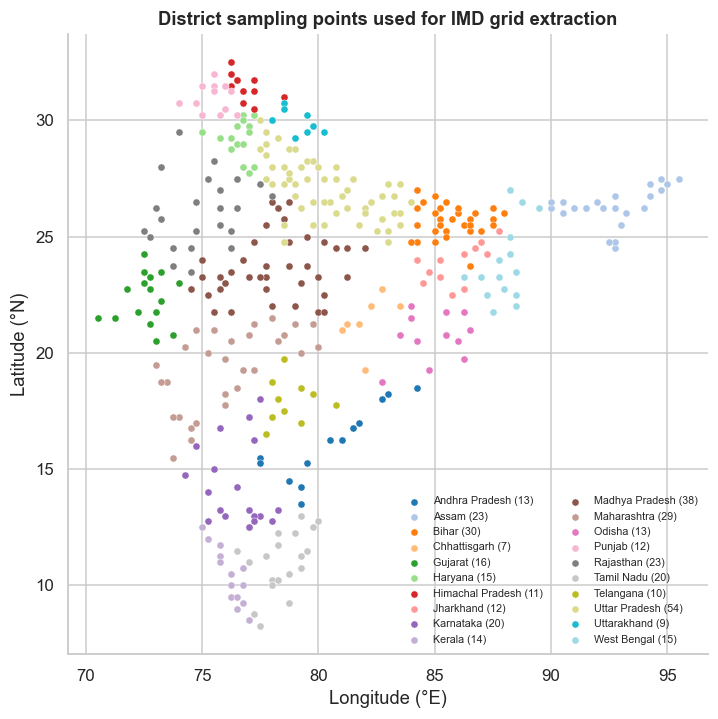

In [2]:
co = pd.read_csv(ROOT/"data/external/district_coordinates_final.csv")
print(co.source.value_counts().to_string()); print("\nsampling point moved by QC refinement:", int(co.moved.sum()), "of", len(co))
fig, ax = plt.subplots(figsize=(7.5, 8))
states = sorted(co.State.unique()); cmap = plt.get_cmap("tab20")
for i, s in enumerate(states):
    g = co[co.State == s]; ax.scatter(g.lon, g.lat, s=22, color=cmap(i % 20), label=f"{s} ({len(g)})", edgecolor="white", linewidth=0.3)
ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)"); ax.set_title("District sampling points used for IMD grid extraction")
ax.legend(fontsize=7, ncol=2, frameon=False, loc="lower right"); ax.set_aspect("equal")
savefig("p2_06_district_map"); plt.show()

## 2 · Quality control: does the extracted rainfall agree with the dataset's own `IMD_RF`?

If a district were geocoded to the wrong place, its extracted annual rainfall would not co-vary with the dataset's `IMD_RF`.
We therefore compare the **annual total** extracted from the IMD grid with `IMD_RF` for all 10,279 district-years.

*Refinement rule (documented, leak-free):* for districts whose **training-year (1990-2009)** correlation was < 0.85 we searched the
5x5 neighbourhood of grid cells and kept the 3x3 block with the best training-year correlation. Only the covariate `IMD_RF` and
training years were used - never yield and never validation/test years.

pooled Pearson r (IMD_RF vs IMD-grid annual total)     : 0.905
pooled Pearson r (IMD_RF vs IMD-grid Jun-Nov total)    : 0.927


saved -> results/figures/p2_06_weather_qc.png


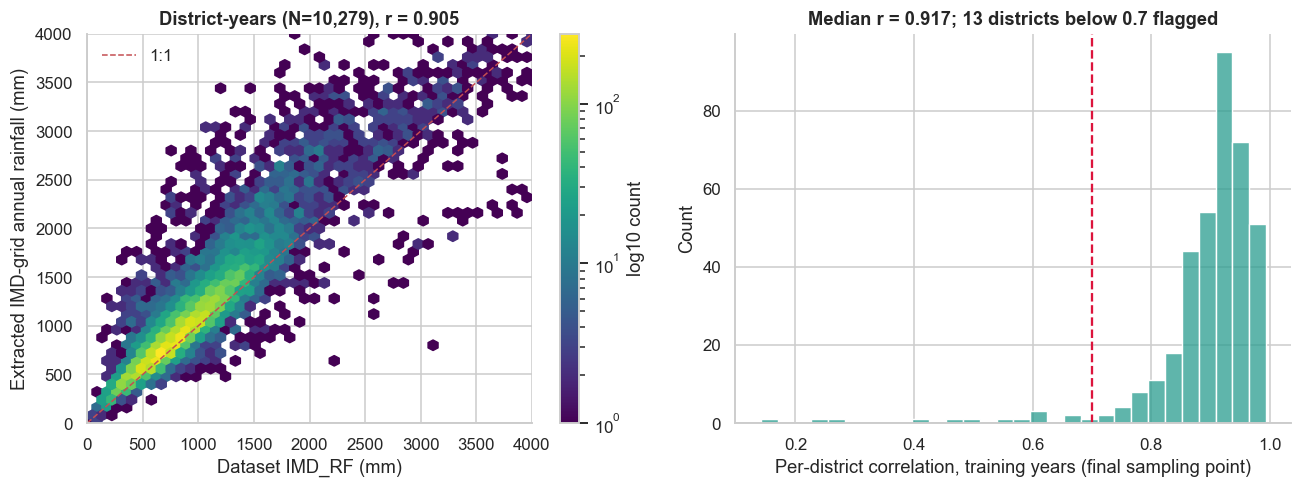

In [3]:
d = pd.read_csv(ROOT/"data/processed/phase1_clean.csv")
q = pd.read_csv(ROOT/"data/external/district_annual_weather_qc.csv")
m = d.merge(q, on=["stable_geographic_id", "Year"])
r_all = m[["IMD_RF", "grid_rain_annual"]].corr().iloc[0, 1]
r_jn = m[["IMD_RF", "grid_rain_jun_nov"]].corr().iloc[0, 1]
print(f"pooled Pearson r (IMD_RF vs IMD-grid annual total)     : {r_all:.3f}")
print(f"pooled Pearson r (IMD_RF vs IMD-grid Jun-Nov total)    : {r_jn:.3f}")
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
hb = axs[0].hexbin(m.IMD_RF, m.grid_rain_annual, gridsize=45, bins="log", cmap="viridis", mincnt=1, extent=(0, 4000, 0, 4000))
lim = [0, 4000]; axs[0].plot(lim, lim, "r--", lw=1, label="1:1"); axs[0].set_xlim(lim); axs[0].set_ylim(lim)
axs[0].set_xlabel("Dataset IMD_RF (mm)"); axs[0].set_ylabel("Extracted IMD-grid annual rainfall (mm)")
axs[0].set_title(f"District-years (N={len(m):,}), r = {r_all:.3f}"); axs[0].legend(frameon=False); plt.colorbar(hb, ax=axs[0], label="log10 count")
sns.histplot(co.r_train_final.dropna(), bins=30, color="#2a9d8f", ax=axs[1])
axs[1].axvline(0.7, color="crimson", ls="--"); axs[1].set_xlabel("Per-district correlation, training years (final sampling point)")
axs[1].set_title(f"Median r = {co.r_train_final.median():.3f}; {int((co.r_train_final < 0.7).sum())} districts below 0.7 flagged")
plt.tight_layout(); savefig("p2_06_weather_qc"); plt.show()

In [4]:
st = (m.groupby("State_Clean").apply(lambda x: pd.Series({
        "districts": x.stable_geographic_id.nunique(),
        "pooled_r": x.IMD_RF.corr(x.grid_rain_annual),
        "mean_IMD_RF_mm": x.IMD_RF.mean(), "mean_grid_mm": x.grid_rain_annual.mean()})).reset_index())
st = st.merge(co.groupby("State").r_train_final.median().rename("median_district_r_train"), left_on="State_Clean", right_index=True)
st.sort_values("pooled_r").to_csv(TAB/"p2_weather_qc_by_state.csv", index=False)
st.sort_values("pooled_r")

,State_Clean,districts,pooled_r,mean_IMD_RF_mm,mean_grid_mm,median_district_r_train
6,Himachal Pradesh,11.000,0.697,919.820,"1,353.005",0.863
15,Tamil Nadu,20.000,0.763,723.418,"1,034.331",0.880
9,Kerala,14.000,0.809,"2,147.164","2,685.424",0.884
18,Uttarakhand,9.000,0.847,"1,095.966","1,362.344",0.871
12,Odisha,13.000,0.847,"1,318.002","1,506.816",0.883
11,Maharashtra,29.000,0.856,"1,218.150","1,227.380",0.919
3,Chhattisgarh,7.000,0.882,"1,188.288","1,271.995",0.910
8,Karnataka,20.000,0.890,955.397,"1,163.336",0.910
0,Andhra Pradesh,13.000,0.895,854.271,"1,015.974",0.851
17,Uttar Pradesh,54.000,0.907,754.078,818.616,0.935


In [5]:
flag = co[co.r_train_final < 0.7][["stable_geographic_id", "State", "District", "source", "r_train_initial", "r_train_final"]]
flag.to_csv(TAB/"p2_flagged_low_qc_districts.csv", index=False)
print("Flagged districts (re-used in the sensitivity analysis of notebook 08):"); flag

Flagged districts (re-used in the sensitivity analysis of notebook 08):


,stable_geographic_id,State,District,source,r_train_initial,r_train_final
32,ASSAM_619,Assam,Karimgang,nominatim,0.677,0.677
108,HIMACHAL_PRADESH_630,Himachal Pradesh,Kinnaur,open-meteo,0.094,0.267
109,HIMACHAL_PRADESH_631,Himachal Pradesh,Kulu,open-meteo,0.583,0.674
137,KARNATAKA_73,Karnataka,Bellary,open-meteo,0.526,0.582
146,KARNATAKA_82,Karnataka,Kodagu,open-meteo,0.400,0.565
201,MAHARASHTRA_102,Maharashtra,Ahmadnagar,open-meteo,0.024,0.142
209,MAHARASHTRA_110,Maharashtra,Bid,open-meteo,-0.006,0.411
233,ODISHA_706,Odisha,Kalahandi,open-meteo,0.446,0.500
280,TAMIL_NADU_510,Tamil Nadu,Kamarajar,nominatim,0.421,0.623
282,TAMIL_NADU_513,Tamil Nadu,V. O. Chidambaram,nominatim,0.541,0.602


**Reading the QC.** Pooled agreement is high (r ≈ 0.90) - the extracted series is an independent re-measurement of the same
climate that the dataset's `IMD_RF` summarises. The level differs (the dataset's value is an average over the district polygon whereas
we sample a ~75 km block at one point), which is why we use the *timing* of rainfall inside a season rather than absolute
equality. A small set of hill/coastal districts keep a low correlation; they are flagged and excluded in a sensitivity analysis later.

## 3 · Weekly rainfall climatology and the 16-week pre-harvest window

The crop calendar (`src/crop_calendar.py`, `docs/crop_calendar_reference.md`) gives each state a Kharif harvest reference week
$T_{ref}$. For district *i* in year *y* the lag features are

$$\text{Rain\_Lag}_k^{(i,y)} = \sum_{\text{days in ISO week } T_{ref}-k} R^{(i)}_{daily}, \qquad k = 1,\dots,16,$$

so $\text{Rain\_Lag}_1$ is the last complete week **before** $T_{ref}$.

saved -> results/figures/p2_06_weekly_climatology_windows.png


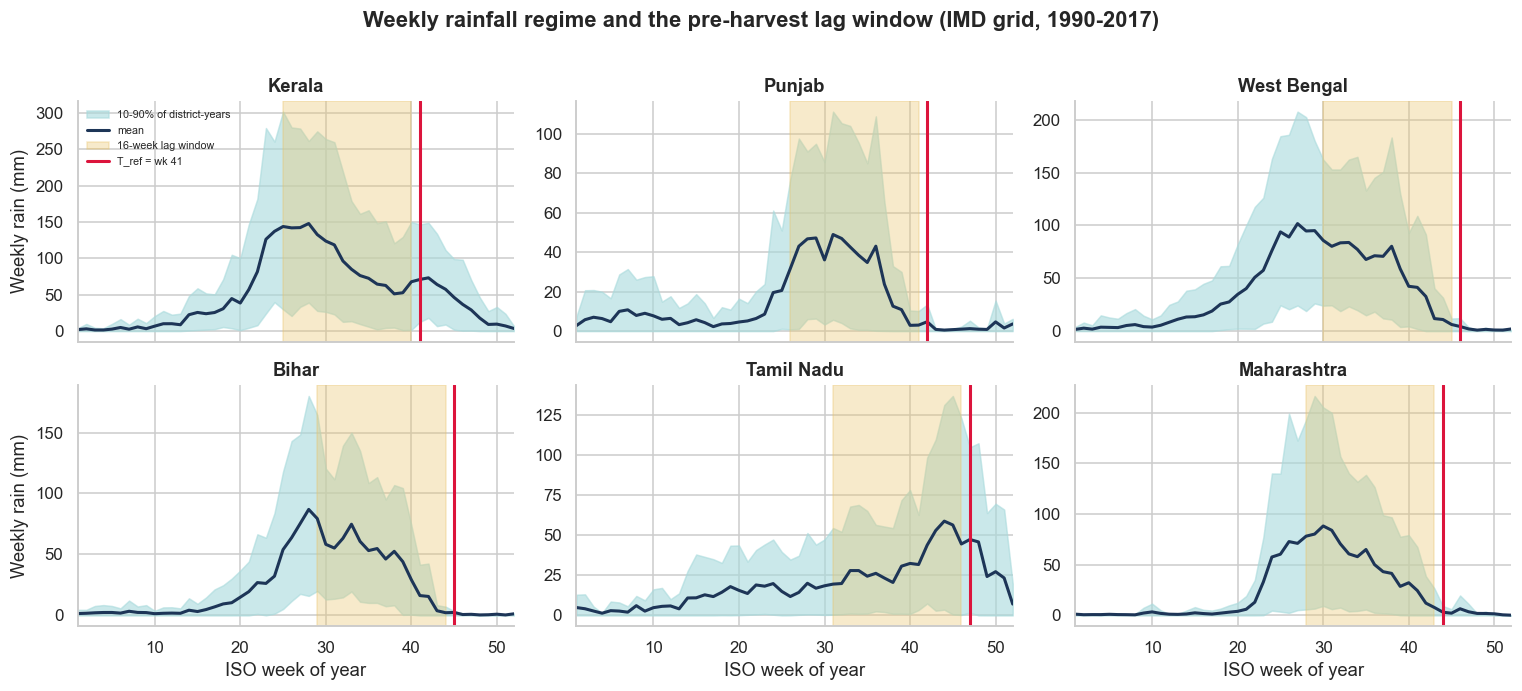

In [6]:
from src.crop_calendar import get_crop_reference_week
wk = pd.read_csv(ROOT/"data/external/district_weekly_weather.csv.gz")
meta = d[["stable_geographic_id", "State_Clean"]].drop_duplicates()
wk = wk.merge(meta, on="stable_geographic_id")
show = ["Kerala", "Punjab", "West Bengal", "Bihar", "Tamil Nadu", "Maharashtra"]
fig, axs = plt.subplots(2, 3, figsize=(14, 6.2), sharex=True)
for ax, s in zip(axs.ravel(), show):
    c = wk[(wk.State_Clean == s) & (wk.iso_week <= 52)].groupby("iso_week").rain_mm.agg(["mean", lambda x: x.quantile(.1), lambda x: x.quantile(.9)])
    c.columns = ["mean", "p10", "p90"]
    t = get_crop_reference_week(s)
    ax.fill_between(c.index, c.p10, c.p90, color="#a8dadc", alpha=.6, label="10-90% of district-years")
    ax.plot(c.index, c["mean"], color="#1d3557", lw=2, label="mean")
    ax.axvspan(t - 16, t - 1, color="#e9c46a", alpha=.35, label="16-week lag window"); ax.axvline(t, color="crimson", lw=2, label=f"T_ref = wk {t}")
    ax.set_title(s); ax.set_xlim(1, 52)
for ax in axs[1]: ax.set_xlabel("ISO week of year")
for ax in axs[:, 0]: ax.set_ylabel("Weekly rain (mm)")
axs[0, 0].legend(fontsize=7, frameon=False); plt.suptitle("Weekly rainfall regime and the pre-harvest lag window (IMD grid, 1990-2017)", y=1.01, fontweight="bold")
plt.tight_layout(); savefig("p2_06_weekly_climatology_windows"); plt.show()

saved -> results/figures/p2_06_lag_heatmap_by_state.png


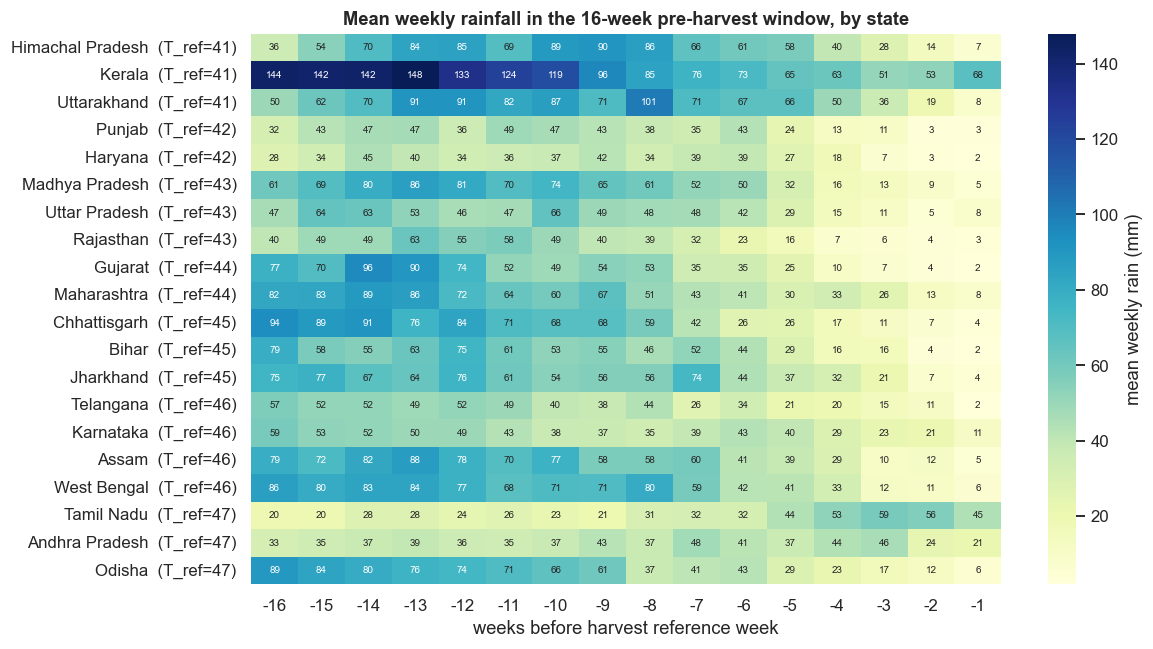

In [7]:
D = pd.read_csv(ROOT/"data/processed/phase2_lag_features.csv.gz")
from src.weather_features import RAIN_LAGS
order = D.groupby("State_Clean").T_ref.first().sort_values().index
H = D.groupby("State_Clean")[RAIN_LAGS].mean().loc[order]
H.columns = [f"-{k}" for k in range(16, 0, -1)]
fig, ax = plt.subplots(figsize=(11, 6.5))
sns.heatmap(H, cmap="YlGnBu", annot=True, fmt=".0f", annot_kws={"size": 6.5}, cbar_kws={"label": "mean weekly rain (mm)"}, ax=ax)
ax.set_yticklabels([f"{s}  (T_ref={int(D[D.State_Clean==s].T_ref.iloc[0])})" for s in order], rotation=0)
ax.set_xlabel("weeks before harvest reference week"); ax.set_ylabel(""); ax.set_title("Mean weekly rainfall in the 16-week pre-harvest window, by state")
savefig("p2_06_lag_heatmap_by_state"); plt.show()

## 4 · Leakage proof: the lag features are strictly causal

In [8]:
from src.weather_features import build_lag_table
clean = pd.read_csv(ROOT/"data/processed/phase1_clean.csv")
base = build_lag_table(clean, wk.drop(columns="State_Clean"), include_tmax=False)
# destroy all weather from the harvest week onwards - no lag feature may change
wk2 = wk.drop(columns="State_Clean").copy()
tref = wk2.merge(meta, on="stable_geographic_id").State_Clean.map(get_crop_reference_week)
wk2.loc[(wk2.iso_week >= tref.values), "rain_mm"] = 1e6
pert = build_lag_table(clean, wk2, include_tmax=False)
same = np.allclose(base[RAIN_LAGS].values, pert[RAIN_LAGS].values)
print("max lag week used  :", int((base.T_ref - 1).max()), "(always < T_ref ->", bool((base.T_ref - 1 < base.T_ref).all()), ")")
print("lags unchanged after poisoning weeks >= T_ref with 1,000,000 mm:", same)
assert same
audit = pd.read_csv(TAB/"p2_lag_dataset_audit.csv"); audit

max lag week used  : 46 (always < T_ref -> True )
lags unchanged after poisoning weeks >= T_ref with 1,000,000 mm: True


,check,value
0,rows,"10,279.000"
1,districts,384.000
2,lag columns,16.000
3,missing rain lags,0.000
4,missing tmax lags,0.000
5,min T_ref,41.000
6,max T_ref,47.000
7,max lag week index (must be < T_ref),46.000
8,mean 16-week rainfall (mm),749.100
9,share of observations with zero rain in some week,0.702


## 5 · How informative can individual weeks be? Collinearity of the lag vector

Adjacent weeks are correlated within a season (monsoon spells). Highly collinear predictors are a classic reason why a lag
vector fails to beat a seasonal sum, and why attributing importance to a single week must be done cautiously.
We measure the correlation of **within-district weekly anomalies**.

saved -> results/figures/p2_06_lag_collinearity.png


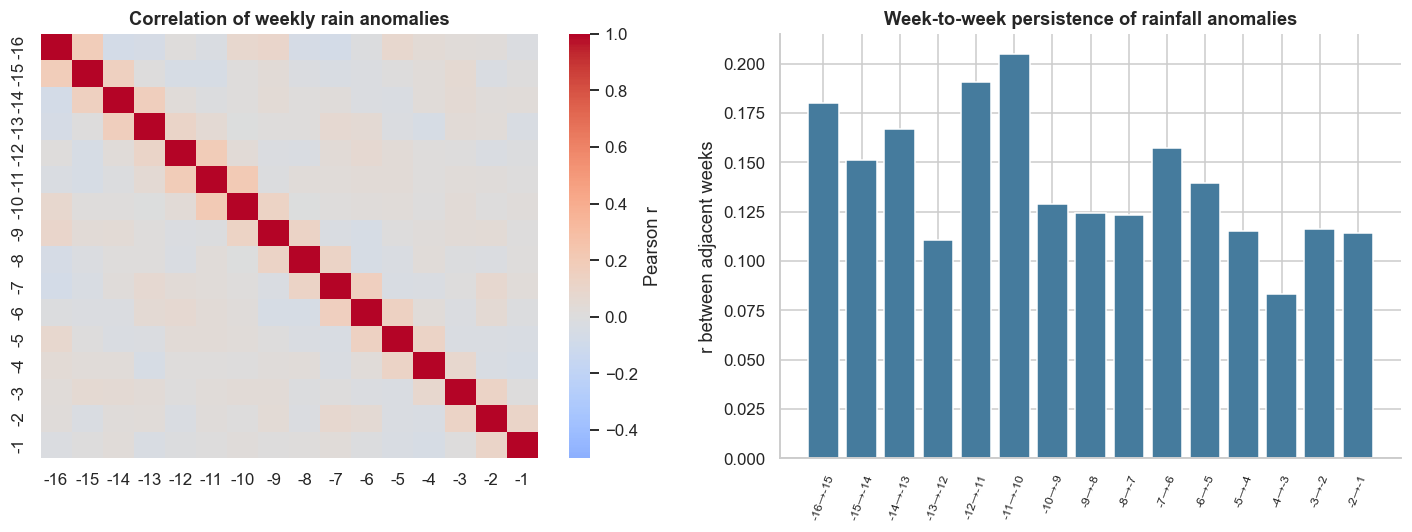

mean off-diagonal r = 0.023;  mean adjacent-week r = 0.140;  max = 0.205
variance inflation factors of the 16 weekly anomalies: min 1.02  max 1.09


In [9]:
from src.experiment import add_rain_anomalies, ANOM_LAGS
A = add_rain_anomalies(D, 2009)
C = A[ANOM_LAGS].corr(); C.index = C.columns = [f"-{k}" for k in range(16, 0, -1)]
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(C, cmap="coolwarm", center=0, vmin=-.5, vmax=1, ax=axs[0], cbar_kws={"label": "Pearson r"}); axs[0].set_title("Correlation of weekly rain anomalies")
lag1 = [C.iloc[i, i + 1] for i in range(15)]
axs[1].bar(range(15), lag1, color="#457b9d"); axs[1].set_xticks(range(15)); axs[1].set_xticklabels([f"{-16+i}→{-15+i}" for i in range(15)], rotation=70, fontsize=8)
axs[1].set_ylabel("r between adjacent weeks"); axs[1].set_title("Week-to-week persistence of rainfall anomalies")
plt.tight_layout(); savefig("p2_06_lag_collinearity"); plt.show()
off = C.values[np.triu_indices(16, 1)]
print(f"mean off-diagonal r = {off.mean():.3f};  mean adjacent-week r = {np.mean(lag1):.3f};  max = {off.max():.3f}")
vif_like = 1 / (1 - (1 - 1 / np.diag(np.linalg.inv(C.values))))
print("variance inflation factors of the 16 weekly anomalies: min %.2f  max %.2f" % (np.diag(np.linalg.inv(C.values)).min(), np.diag(np.linalg.inv(C.values)).max()))

### Take-aways of notebook 06
* A time-resolved, observation-based daily rainfall record now exists for all 384 districts; pooled agreement with the dataset's own
  `IMD_RF` is r ≈ 0.90 and every flagged district is tracked for sensitivity analysis.
* All 16 lag columns are strictly earlier than the harvest reference week (formal poisoning test passed), for 10,279/10,279 district-years,
  with no missing values.
* Weekly anomalies are only weakly correlated across weeks, so the lag vector is not trivially redundant - timing *can* carry information
  beyond the seasonal sum. Whether it actually improves forecasts is the subject of notebooks 07-10.